In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Load Image as grayscale
img = cv2.imread('../Data/Dog.jpg', cv2.IMREAD_GRAYSCALE)

In [4]:
#function to calculate histogram of an image
def histogram(img):
    frequency = np.zeros(256, dtype=np.int64)

    for pixel in img.ravel():
        frequency[pixel] += 1

    return frequency
    

In [5]:
#create histogram of the image
hist = histogram(img)

In [6]:
#Function to find Otsu threshold
def otsu_threshold(histogram):
    best_threshold = 0
    highest_variance = 0
    
    gray_levels = np.arange(256)
    
    for level in range(256):
        background = histogram[:level+1]
        foreground = histogram[level+1:]
        
        count_background = np.sum(background)
        count_foreground = np.sum(foreground)
        
        if count_background == 0 or count_foreground == 0:
            continue
        
        mean_background = np.sum(gray_levels[:level+1] * background) / count_background
        mean_foreground = np.sum(gray_levels[level+1:] * foreground) / count_foreground
        
        between_variance = (count_background * count_foreground * (mean_background - mean_foreground) ** 2)
        
        if between_variance > highest_variance:
            highest_variance = between_variance
            best_threshold = level

    return best_threshold

In [7]:
#Calculate threshold
threshold = otsu_threshold(hist)
print(f"Otsu's threshold value: {threshold}")

Otsu's threshold value: 147


In [ ]:
#create binary image 
binary_image = np.where(img > threshold, 255, 0).astype(np.uint8)

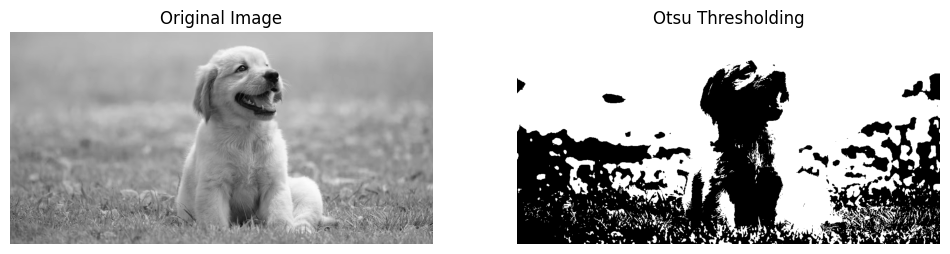

In [10]:
#Display Output
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap='gray')
plt.title('Otsu Thresholding')
plt.axis('off')
plt.show()